# One case, end to end

This notebook takes VitalDB case 19 through the four steps of the README: load the cleaned pressure and flow, find the beats, fit a 3-element Windkessel model to one window, and compare a stroke volume estimate with the CardioQ monitor. Use it as a template and replace the parts you want to do differently.

The first run downloads the case (about 45 MB). The plots use VitalDB data (Lee et al. 2022, CC BY 4.0).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from vitaldb_hemo import beats, cardioq, evaluate, identify, windkessel

## 1. Load the case

`cardioq.load` returns the pressure `c.p` [mmHg] and flow `c.q` [mL/s] on one clock at `c.fs` = 180 Hz, and a table of 10 s windows. Count why windows were rejected:

In [2]:
c = cardioq.load(19)
print(
    f"{len(c.p) / c.fs / 3600:.1f} h at {c.fs:.0f} Hz, flow scale {c.gain:.2f} mL/s per CardioQ/FLOW unit"
)
c.windows.reason.replace("", "ok").value_counts()

7.7 h at 180 Hz, flow scale 1.64 mL/s per CardioQ/FLOW unit


reason
ok          1809
missing      491
pressure     159
beats        159
device       101
gain          38
Name: count, dtype: int64

Pick a usable window from the middle of the case and plot it.

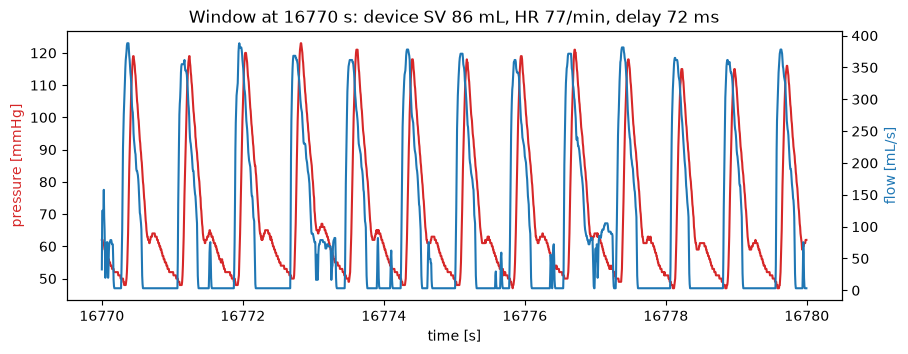

In [3]:
w = c.windows[c.windows.ok]
r = w.iloc[len(w) // 2]
t, p, q = c.segment(r.t0, r.t1)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, p, "C3")
ax.set_xlabel("time [s]")
ax.set_ylabel("pressure [mmHg]", color="C3")
ax2 = ax.twinx()
ax2.plot(t, q, "C0")
ax2.set_ylabel("flow [mL/s]", color="C0")
ax.set_title(
    f"Window at {r.t0:.0f} s: device SV {r.sv:.0f} mL, HR {r.hr:.0f}/min, delay {1000 * r.delay:.0f} ms"
)
plt.show()

## 2. Find the beats

Onsets in the pressure and in the flow. The flow beats start earlier by the delay, the time the pulse takes to reach the wrist.

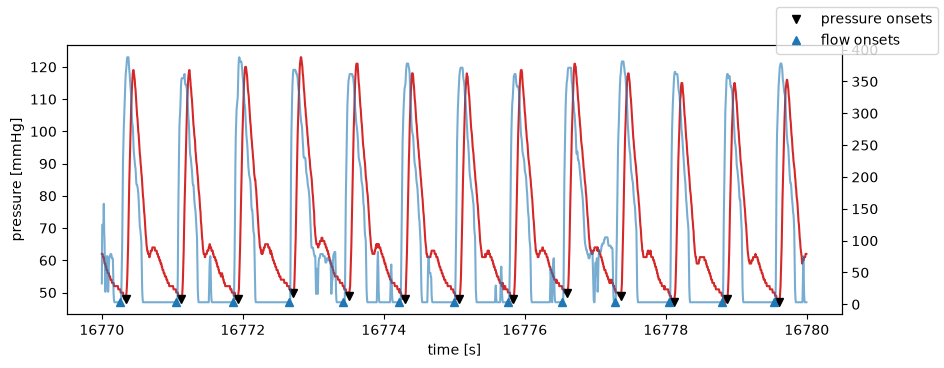

,t,sbp,dbp,map,pp,hr,dpdt_max,ok
0,0.3,119.0,48.0,69.1,71.0,76.1,1070.3,True
1,1.1,119.0,48.0,69.1,71.0,75.0,1027.7,True
2,1.9,120.0,48.0,71.0,72.0,76.1,1064.7,True
3,2.7,123.0,49.0,72.6,74.0,76.1,1117.4,True
4,3.5,121.0,48.0,70.4,73.0,75.5,1078.0,True
5,4.3,118.0,48.0,68.9,70.0,77.7,1027.6,True
6,5.1,118.0,47.0,69.0,71.0,78.3,1039.4,True
7,5.8,119.0,48.0,70.5,71.0,78.3,1056.5,True
8,6.6,121.0,49.0,71.6,72.0,79.4,1046.4,True
9,7.4,118.0,47.0,69.5,71.0,79.4,1072.8,True


In [4]:
on_p, on_q = beats.onsets(p, c.fs), beats.onsets(q, c.fs)
f = beats.features(p, c.fs, on_p)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, p, "C3")
ax.plot(t[on_p], p[on_p], "v", color="k", label="pressure onsets")
ax.set_ylabel("pressure [mmHg]")
ax2 = ax.twinx()
ax2.plot(t, q, "C0", alpha=0.6)
ax2.plot(t[on_q], q[on_q], "^", color="C0", label="flow onsets")
ax.set_xlabel("time [s]")
fig.legend(loc="upper right")
plt.show()
f.round(1)

## 3. Fit a 3-element Windkessel model

Shift the pressure back by the window's delay so that the beats line up with the flow, then fit `[Rp, C, Rc]` by output error.

Rp = 0.497 mmHg s/mL, C = 5.87 mL/mmHg, Rc = 0.152 mmHg s/mL, RMS error 6.3 mmHg


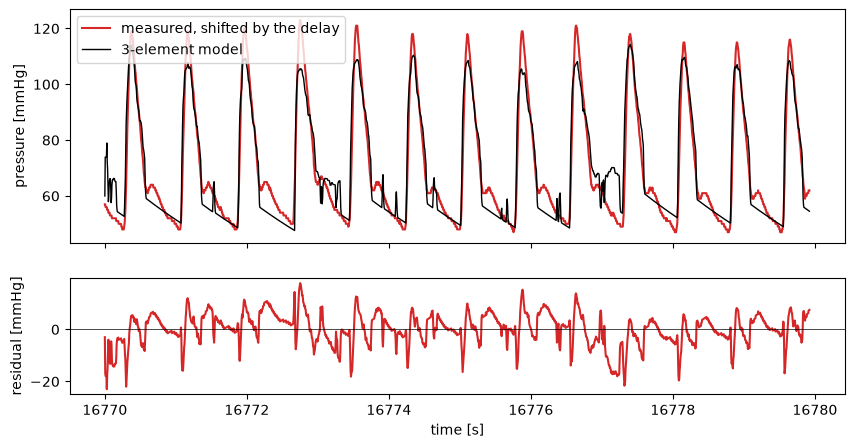

In [5]:
k = round(r.delay * c.fs)
qs, ps, ts = q[: len(q) - k], p[k:], t[: len(t) - k]
fit = identify.identify([1.0, 1.5, 0.05], qs, ps, 1 / c.fs, model=windkessel.wk3)
p_model = windkessel.simulate(fit.theta, fit.x0, qs, 1 / c.fs, model=windkessel.wk3)

rp, cc, rc = fit.theta
print(
    f"Rp = {rp:.3f} mmHg s/mL, C = {cc:.2f} mL/mmHg, Rc = {rc:.3f} mmHg s/mL, RMS error {np.sqrt(fit.mse):.1f} mmHg"
)

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(ts, ps, "C3", label="measured, shifted by the delay")
ax[0].plot(ts, p_model, "k", lw=1, label="3-element model")
ax[0].set_ylabel("pressure [mmHg]")
ax[0].legend()
ax[1].plot(ts, ps - p_model, "C3")
ax[1].axhline(0, color="k", lw=0.5)
ax[1].set_ylabel("residual [mmHg]")
ax[1].set_xlabel("time [s]")
plt.show()

The residual is not white noise: it repeats with every beat. The model misses part of the waveform, partly because it describes pressure in the aorta and this is pressure at the wrist. The spikes in the model pressure during diastole come from spikes in the Doppler flow signal, which `Rc` passes straight through.

## 4. Compare with the device

A simple baseline estimate: stroke volume proportional to pulse pressure, calibrated on the first 5 usable minutes (30 windows) and left out of the comparison.

bias -5.2 mL, limits -23.4 to +13.0 mL, percentage error 22 %
concordance of 5 min changes 0.73 (15 pairs)


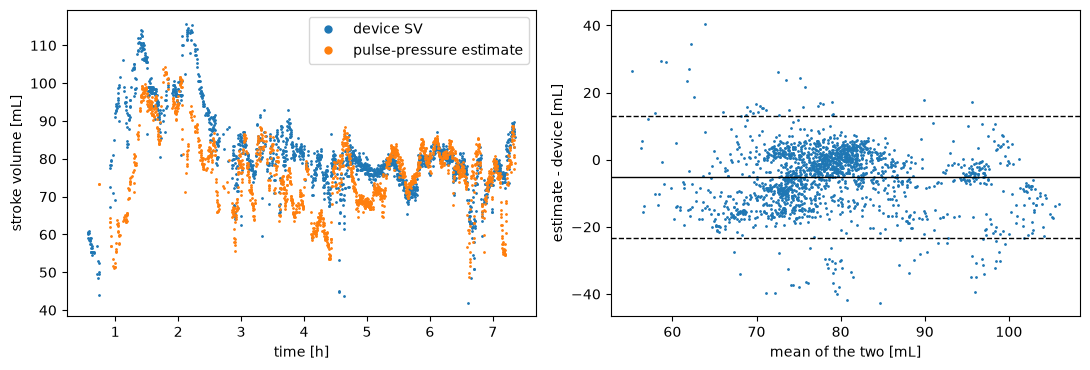

In [6]:
fc = beats.features(c.p, c.fs, beats.onsets(c.p, c.fs))
pp = fc[fc.ok].groupby(fc.t // 10 * 10).pp.mean().reindex(w.t0).to_numpy()
sv = w.sv.to_numpy()
est = pp * np.mean(sv[:30] / pp[:30])

a = evaluate.agreement(est[30:], sv[30:])
rate, n = evaluate.concordance(est[30::30], sv[30::30])
print(
    f"bias {a.bias:+.1f} mL, limits {a.loa[0]:.1f} to {a.loa[1]:+.1f} mL, percentage error {a.percentage_error:.0f} %"
)
print(f"concordance of 5 min changes {rate:.2f} ({n} pairs)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(w.t0 / 3600, sv, ".", ms=2, label="device SV")
ax[0].plot(w.t0[30:] / 3600, est[30:], ".", ms=2, label="pulse-pressure estimate")
ax[0].set_xlabel("time [h]")
ax[0].set_ylabel("stroke volume [mL]")
ax[0].legend(markerscale=5)
m, d = (est[30:] + sv[30:]) / 2, est[30:] - sv[30:]
ax[1].plot(m, d, ".", ms=2)
for v, ls in [(a.bias, "-"), (a.loa[0], "--"), (a.loa[1], "--")]:
    ax[1].axhline(v, color="k", lw=1, ls=ls)
ax[1].set_xlabel("mean of the two [mL]")
ax[1].set_ylabel("estimate - device [mL]")
plt.tight_layout()
plt.show()

## Next

- Run the fit on every usable window and look at how the parameters change over the case.
- Replace the pulse-pressure baseline with your own estimator, and evaluate it the same way on the development cases.
- Pool cases with `evaluate.agreement(..., subject=caseids)`, so that the limits of agreement account for several windows per patient.